# SETUP

In [1]:
from pandas._libs.tslibs.offsets import SemiMonthOffset
import pandas as pd 
import seaborn as sns   
import numpy as np  
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, auc, precision_recall_curve, confusion_matrix, classification_report
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

In [2]:
df = pd.read_csv('creditcard.csv')

# EDA

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape()

TypeError: 'tuple' object is not callable

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [ ]:
df.isnull().sum().sum()

np.int64(0)

Tabel Frekuensi Tiap Kelas Class:
Class
0    284315
1       492
Name: count, dtype: int64


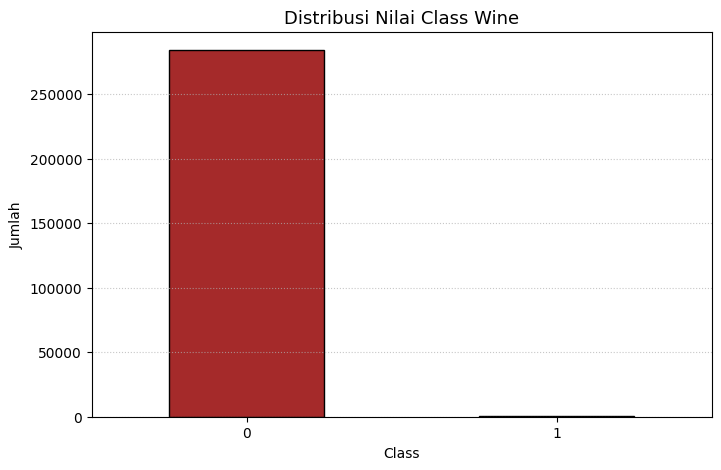

In [ ]:
print("Tabel Frekuensi Tiap Kelas Class:")
print(df['Class'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
df['Class'].value_counts().sort_index().plot(
    kind='bar', color='darkwine' if 'darkwine' in plt.colormaps else 'brown', edgecolor='black'
)

plt.title('Distribusi Nilai Class Wine', fontsize=13)
plt.xlabel('Class')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

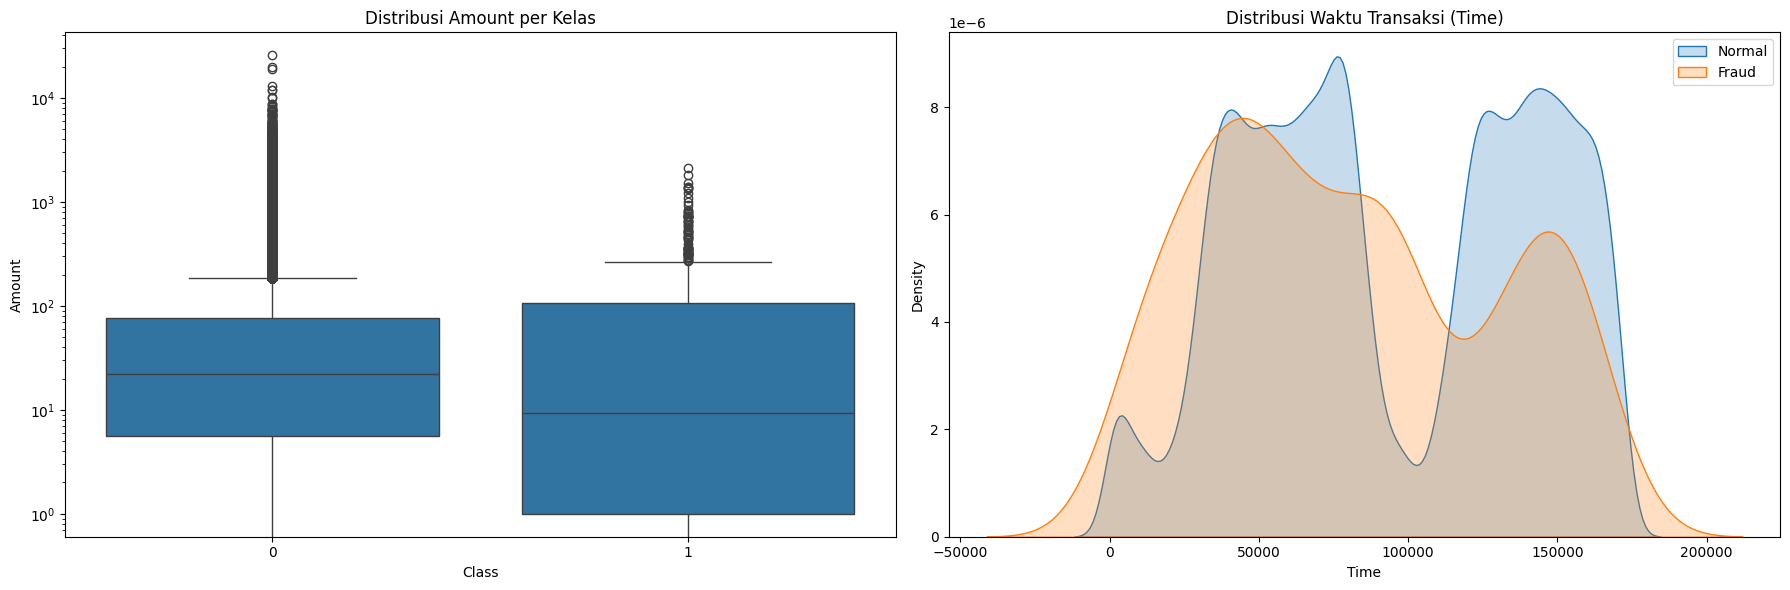

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# Distribusi Amount pada transaksi Normal vs Fraud
sns.boxplot(x='Class', y='Amount', data=df, ax=ax[0])
ax[0].set_title('Distribusi Amount per Kelas')
ax[0].set_yscale('log')

# Distribusi Time pada transaksi Normal vs Fraud (KDE)
sns.kdeplot(df[df['Class'] == 0]['Time'], label='Normal', fill=True, ax=ax[1])
sns.kdeplot(df[df['Class'] == 1]['Time'], label='Fraud', fill=True, ax=ax[1])
ax[1].set_title('Distribusi Waktu Transaksi (Time)')
ax[1].legend()

plt.tight_layout()
plt.show()

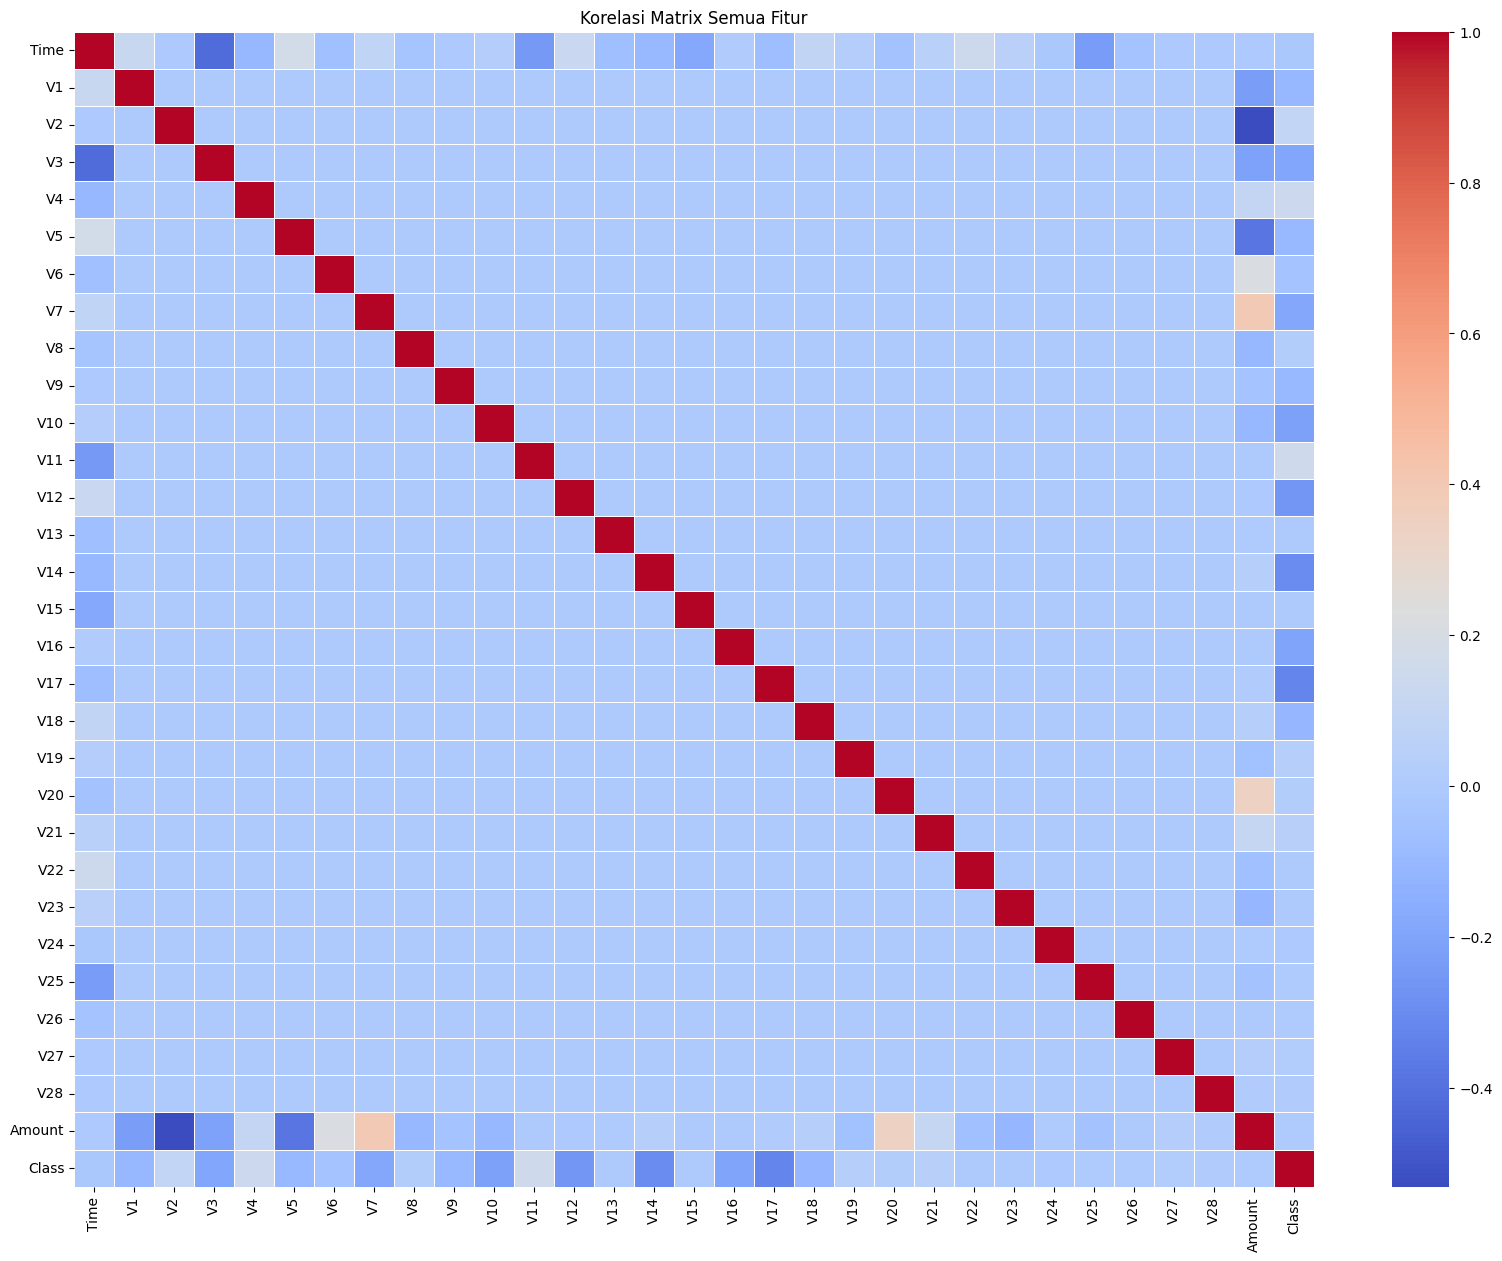

Korelasi fitur dengan Class (diurutkan):
Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
V20      0.020090
V8       0.019875
V27      0.017580
V28      0.009536
Name: Class, dtype: float64
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
Name: Class, dtype: float64


In [ ]:
plt.figure(figsize=(20, 15))

corr_matrix = df.corr()

sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title('Korelasi Matrix Semua Fitur')
plt.show()

# Cek fitur apa saja yang paling berkorelasi dengan target 'Class'
print("Korelasi fitur dengan Class (diurutkan):")
print(corr_matrix['Class'].sort_values(ascending=False).head(10))
print(corr_matrix['Class'].sort_values(ascending=True).head(10))

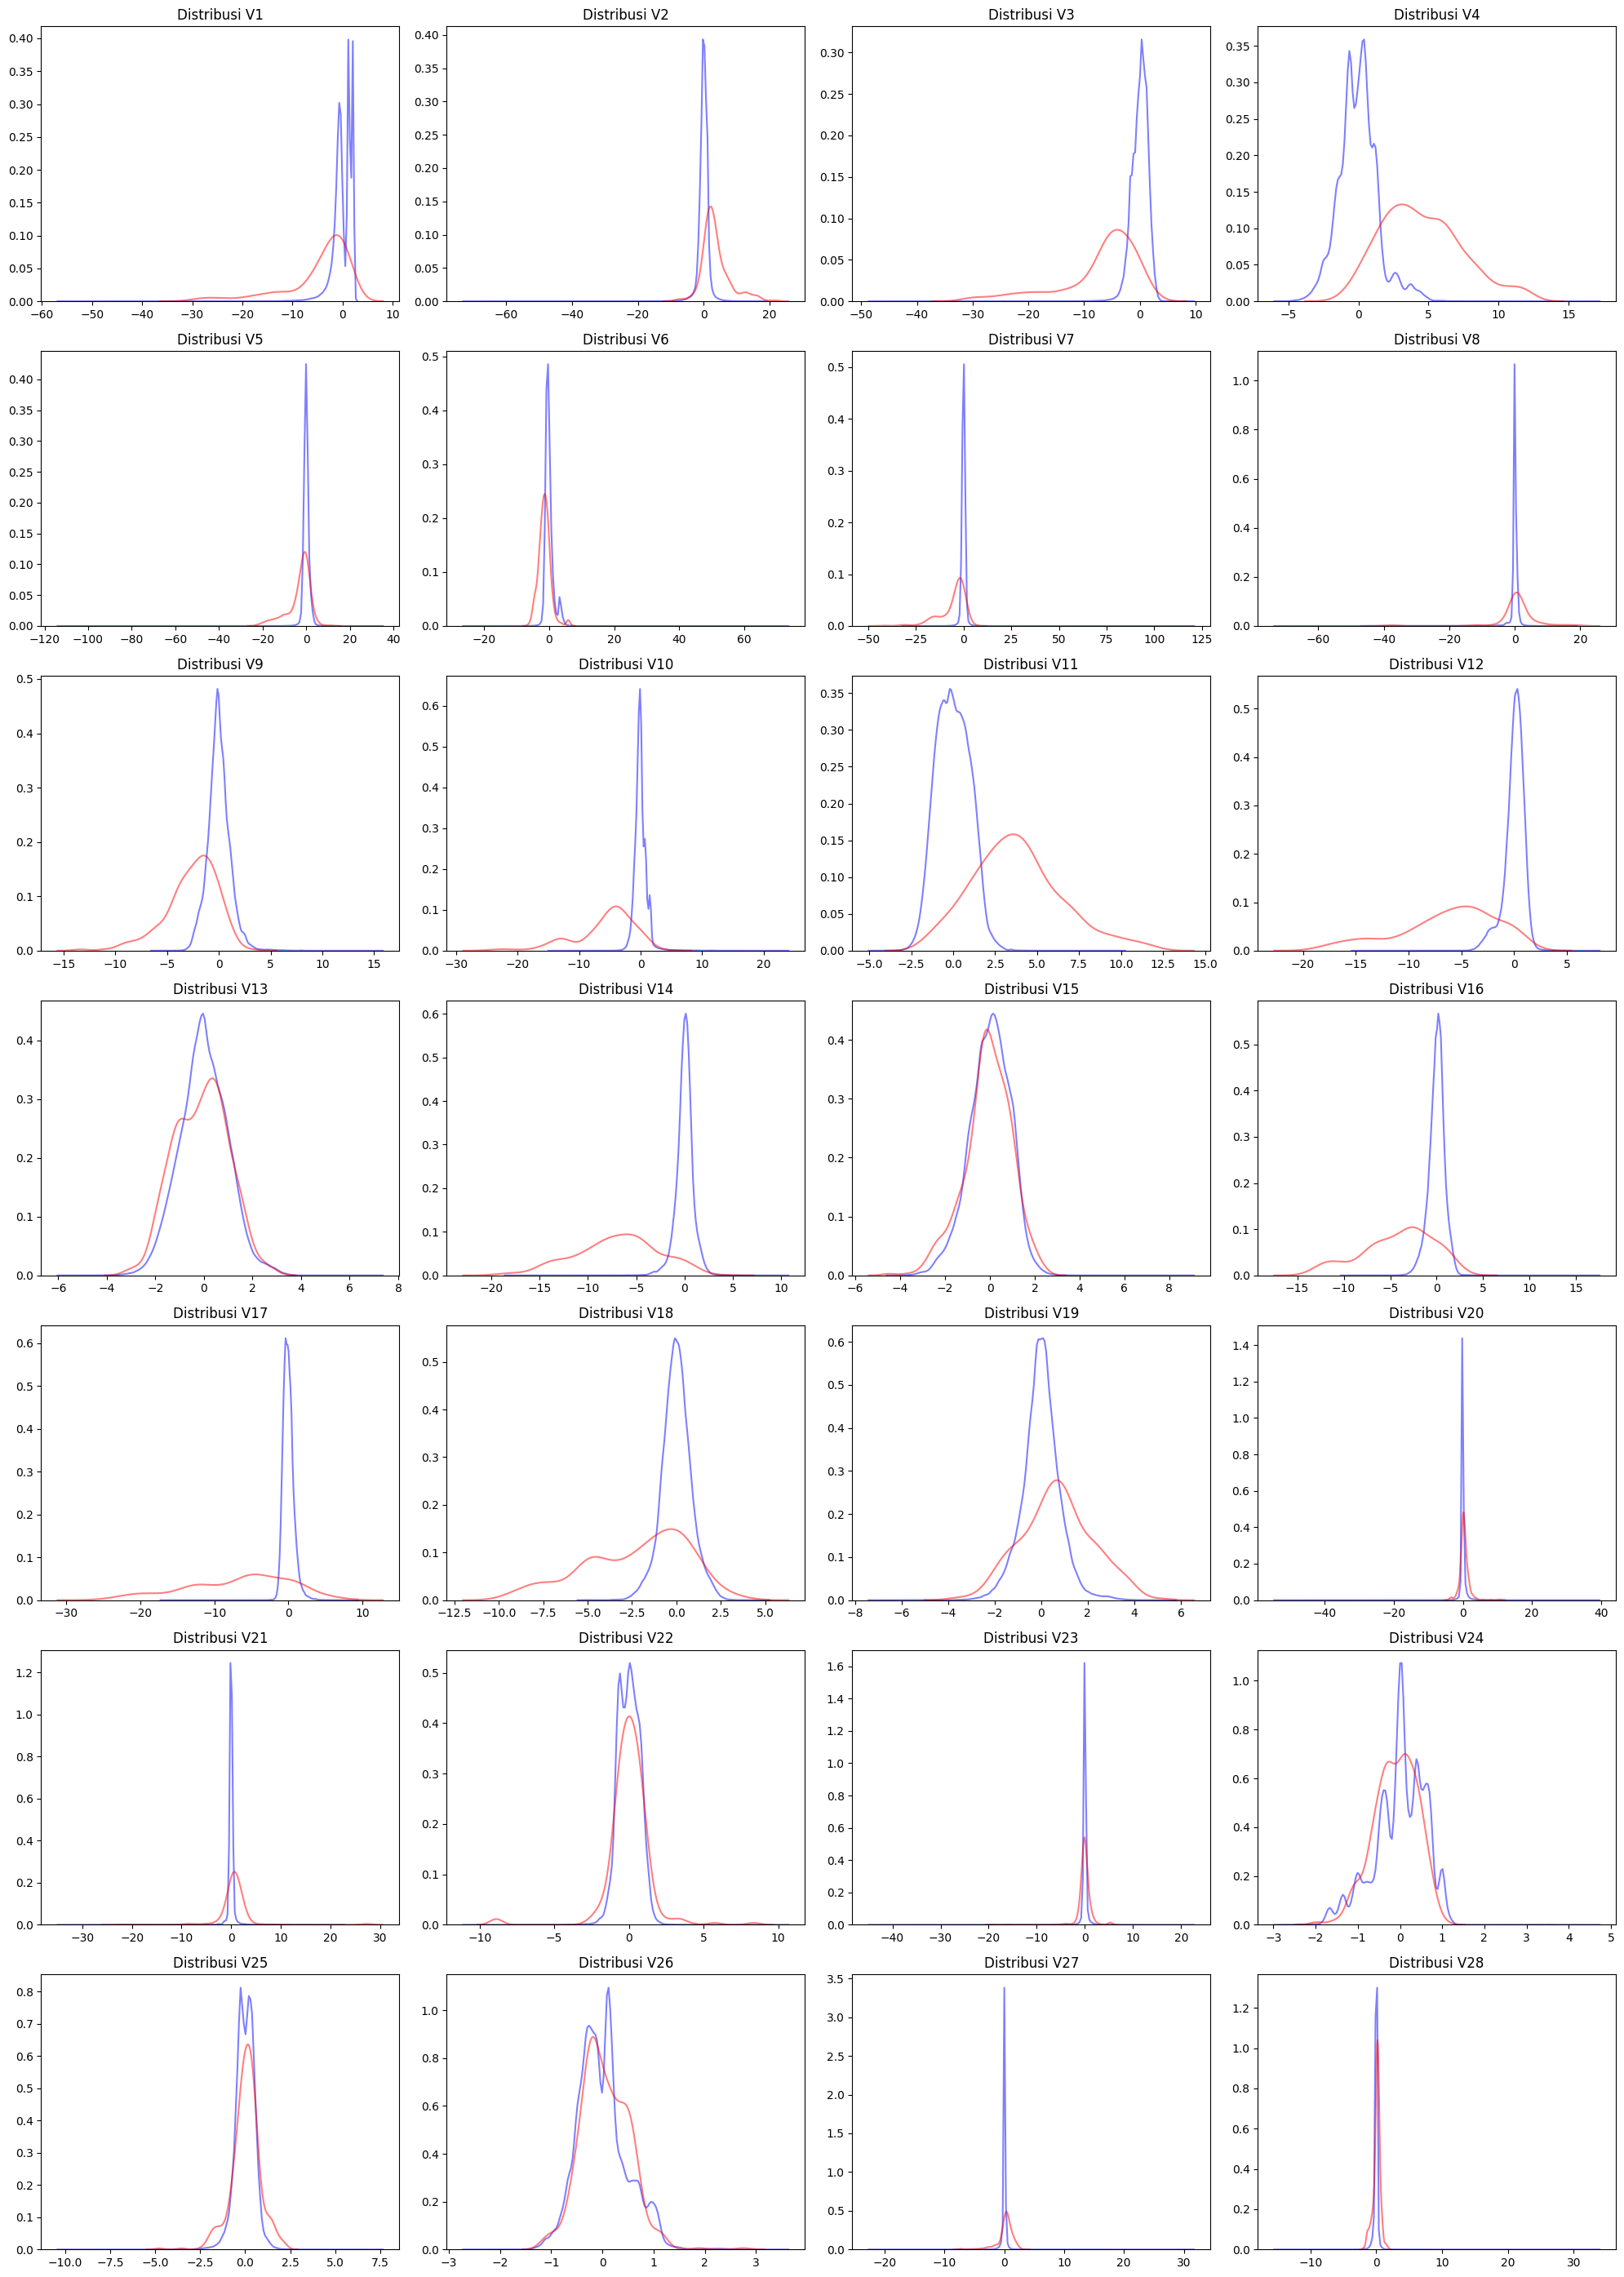

In [ ]:
v_features = df.columns[1:29] 

fig, axes = plt.subplots(nrows=7, ncols=4, figsize=(20, 28))
axes = axes.flatten()

for i, col in enumerate(v_features):
    sns.kdeplot(df[df['Class'] == 0][col], label='Normal', ax=axes[i], color='blue', alpha=0.5)
    sns.kdeplot(df[df['Class'] == 1][col], label='Fraud', ax=axes[i], color='red', alpha=0.5)
    axes[i].set_title(f'Distribusi {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(len(v_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# PREPROCESSING

In [ ]:
# Pisahkan fitur (X) dan target (y)
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Fraud di Train Set: {sum(y_train == 1)}")
print(f"Jumlah Fraud di Test Set: {sum(y_test == 1)}")

neg_count = sum(y_train == 0)
pos_count = sum(y_train == 1)
scale_weight = neg_count / pos_count
print(f"Rekomendasi nilai scale_pos_weight: {scale_weight:.2f}")

Jumlah Fraud di Train Set: 394
Jumlah Fraud di Test Set: 98
Rekomendasi nilai scale_pos_weight: 577.29


In [ ]:
# Inisialisasi scaler
rob_scaler = RobustScaler()

# Fit dan transform HANYA di X_train
X_train['scaled_amount'] = rob_scaler.fit_transform(X_train['Amount'].values.reshape(-1, 1))
X_train['scaled_time'] = rob_scaler.fit_transform(X_train['Time'].values.reshape(-1, 1))

# Transform saja di X_test
X_test['scaled_amount'] = rob_scaler.transform(X_test['Amount'].values.reshape(-1, 1))
X_test['scaled_time'] = rob_scaler.transform(X_test['Time'].values.reshape(-1, 1))

# Drop kolom aslinya
X_train.drop(['Time', 'Amount'], axis=1, inplace=True)
X_test.drop(['Time', 'Amount'], axis=1, inplace=True)

# Pindahkan kolom scaled ke depan agar rapi (Opsional)
scaled_amount_train = X_train['scaled_amount']
scaled_time_train = X_train['scaled_time']
X_train.drop(['scaled_amount', 'scaled_time'], axis=1, inplace=True)
X_train.insert(0, 'scaled_amount', scaled_amount_train)
X_train.insert(1, 'scaled_time', scaled_time_train)

scaled_amount_test = X_test['scaled_amount']
scaled_time_test = X_test['scaled_time']
X_test.drop(['scaled_amount', 'scaled_time'], axis=1, inplace=True)
X_test.insert(0, 'scaled_amount', scaled_amount_test)
X_test.insert(1, 'scaled_time', scaled_time_test)

print("Scaling selesai. Kolom Time dan Amount sudah disesuaikan.")

Scaling selesai. Kolom Time dan Amount sudah disesuaikan.


In [ ]:
# Inisialisasi SMOTE
smote = SMOTE(random_state=42)

# Resample HANYA data train
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Sebelum SMOTE, jumlah Fraud: {sum(y_train == 1)}")
print(f"Setelah SMOTE, jumlah Fraud: {sum(y_train_smote == 1)}")
print(f"Setelah SMOTE, jumlah Normal: {sum(y_train_smote == 0)}")

Sebelum SMOTE, jumlah Fraud: 394
Setelah SMOTE, jumlah Fraud: 227451
Setelah SMOTE, jumlah Normal: 227451


Training model Random Forest pada Data Asli (Imbalanced)...

=== Evaluasi Random Forest (Tanpa SMOTE) ===
Confusion Matrix:


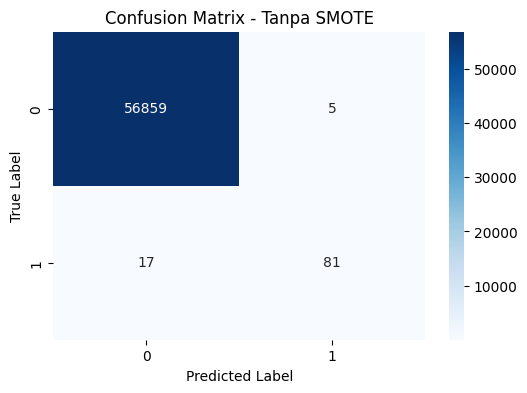


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.83      0.88        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9519
PR-AUC Score: 0.8679


In [ ]:
# Inisialisasi Model Random Forest (Menggunakan parameter default)
rf_model_original = RandomForestClassifier(random_state=42, n_jobs=-1)

print("Training model Random Forest pada Data Asli (Imbalanced)...")
rf_model_original.fit(X_train, y_train)

# Prediksi di test set
y_pred_orig = rf_model_original.predict(X_test)
y_pred_prob_orig = rf_model_original.predict_proba(X_test)[:, 1]

print("\n=== Evaluasi Random Forest (Tanpa SMOTE) ===")
print("Confusion Matrix:")
cm_orig = confusion_matrix(y_test, y_pred_orig)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_orig, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Tanpa SMOTE')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_orig))

# Precision-Recall AUC
precision_orig, recall_orig, _ = precision_recall_curve(y_test, y_pred_prob_orig)
pr_auc_orig = auc(recall_orig, precision_orig)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob_orig):.4f}")
print(f"PR-AUC Score: {pr_auc_orig:.4f}")

Training model Random Forest pada Data SMOTE...

=== Evaluasi Random Forest (Dengan SMOTE) ===
Confusion Matrix:


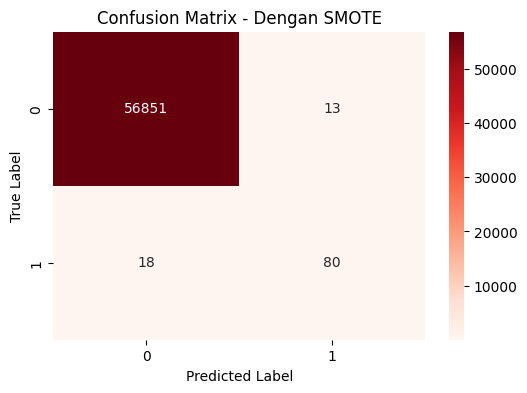


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.86      0.82      0.84        98

    accuracy                           1.00     56962
   macro avg       0.93      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9799
PR-AUC Score: 0.8636


In [ ]:
# Inisialisasi Model Random Forest
rf_model_smote = RandomForestClassifier(random_state=42, n_jobs=-1)

print("Training model Random Forest pada Data SMOTE...")
rf_model_smote.fit(X_train_smote, y_train_smote)

# Prediksi di test set (Gunakan X_test asli, BUKAN yang di-SMOTE)
y_pred_smote = rf_model_smote.predict(X_test)
y_pred_prob_smote = rf_model_smote.predict_proba(X_test)[:, 1]

print("\n=== Evaluasi Random Forest (Dengan SMOTE) ===")
print("Confusion Matrix:")
cm_smote = confusion_matrix(y_test, y_pred_smote)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Reds')
plt.title('Confusion Matrix - Dengan SMOTE')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

# Precision-Recall AUC
precision_smote, recall_smote, _ = precision_recall_curve(y_test, y_pred_prob_smote)
pr_auc_smote = auc(recall_smote, precision_smote)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob_smote):.4f}")
print(f"PR-AUC Score: {pr_auc_smote:.4f}")

**Alasan Akurasi tidak cukup:** Kedua model menghasilkan tingkat akurasi 1.00 (100%). Pada dataset dengan distribusi fraud di bawah 1%, model yang menebak "Normal" terus-menerus akan tetap mendapat akurasi 99.8%. Oleh karena itu, *Precision*, *Recall*, dan *PR-AUC* adalah metrik yang valid.

